In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import umap
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
from sklearn import preprocessing
from sklearn.pipeline import make_pipeline
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

sns.set(style='white', context='notebook', rc={'figure.figsize':(14,10)})
combined_augmented_data = pd.read_csv("C:/Users/Zach/Documents/Duke/covspot_analysis/screen_analysis/variant_detection_codebase/Embedded_FS/combined_augmented_data.csv")
# pd.read_csv("/home/surface-lab/variant_detection_codebase/Embedded_FS/combined_augmented_data.csv")

# Define x_train as just the cab values
colnames = combined_augmented_data.columns
cab_fluorescence_vals = combined_augmented_data[colnames[3:len(colnames)]]

target_vector_labels = combined_augmented_data['target_vector']
target_vector_vals = np.unique(target_vector_labels)

# Data needs to be centered and scaled with replicate and Conc. removed for now
simple_scaler = preprocessing.StandardScaler().fit(cab_fluorescence_vals)
normalized_cab_fluorescence = simple_scaler.transform(cab_fluorescence_vals)

# Obtain only values from concentrations greater than 0.1 ng/ml, get y_labels and scale
# This removes higher levels values
trimmed_augmented_data = combined_augmented_data[combined_augmented_data['Conc.'] > 0.1]
trimmed_data_y_labels = trimmed_augmented_data['target_vector']
trimmed_cab_fluorescence_vals = trimmed_augmented_data[colnames[3:len(colnames)]]
trimmed_normalized_cab_fluorescence = preprocessing.StandardScaler().fit_transform(trimmed_cab_fluorescence_vals)

# Only obtain values with concentrations between 0.1 and 100 to remove some of the higher leve
medium_trimmed_augmented_data = trimmed_augmented_data[(combined_augmented_data['Conc.'] > 10) & (combined_augmented_data['Conc.'] <= 125)]
medium_trimmed_data_y_labels = medium_trimmed_augmented_data['target_vector']
medium_trimmed_cab_fluorescence = medium_trimmed_augmented_data[colnames[3:len(colnames)]]
medium_trimmed_normalize_cab_fluorescence = preprocessing.StandardScaler().fit_transform(medium_trimmed_cab_fluorescence)

# Importing Knn imputed data - the imputation occurs over the whole dataset with the class known - NOTE: this data set does not include cab13 while the others do
# outlier_removed_data = pd.read_csv("C:/Users/Zach/Documents/Duke/covspot_analysis/screen_analysis/variant_detection_codebase/Embedded_FS/augmented_data_knn_imputed_outliers.csv")
# outlier_colnames = outlier_removed_data.columns
# outlier_trimmed_data = outlier_removed_data[(combined_augmented_data['Conc.'] > 1) & (outlier_removed_data['Conc.'] < 249)]
# outlier_trimmed_data_y_labels = outlier_trimmed_data['target_vector']
# outlier_trimmed_cab_fluorescence = outlier_trimmed_data[outlier_colnames[3:len(outlier_colnames)]]
# outlier_trimmed_normalize_cab_fluorescence = preprocessing.StandardScaler().fit_transform(outlier_trimmed_cab_fluorescence)

# sns.pairplot(trimmed_augmented_data.drop(["Replicate", "Conc."], axis=1), hue='target_vector')

C:\Users\Zach\AppData\Local\Temp\ipykernel_38008\4096173119.py:35: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  medium_trimmed_augmented_data = trimmed_augmented_data[(combined_augmented_data['Conc.'] > 10) & (combined_augmented_data['Conc.'] <= 125)]


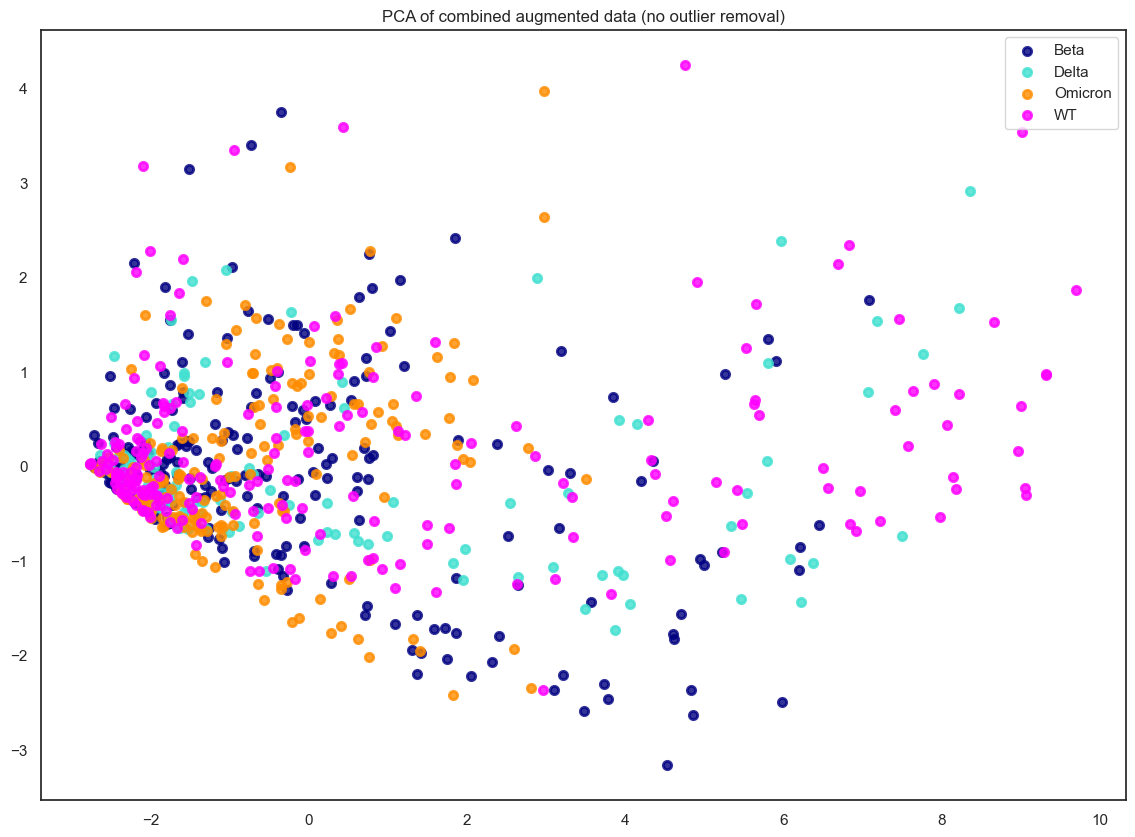

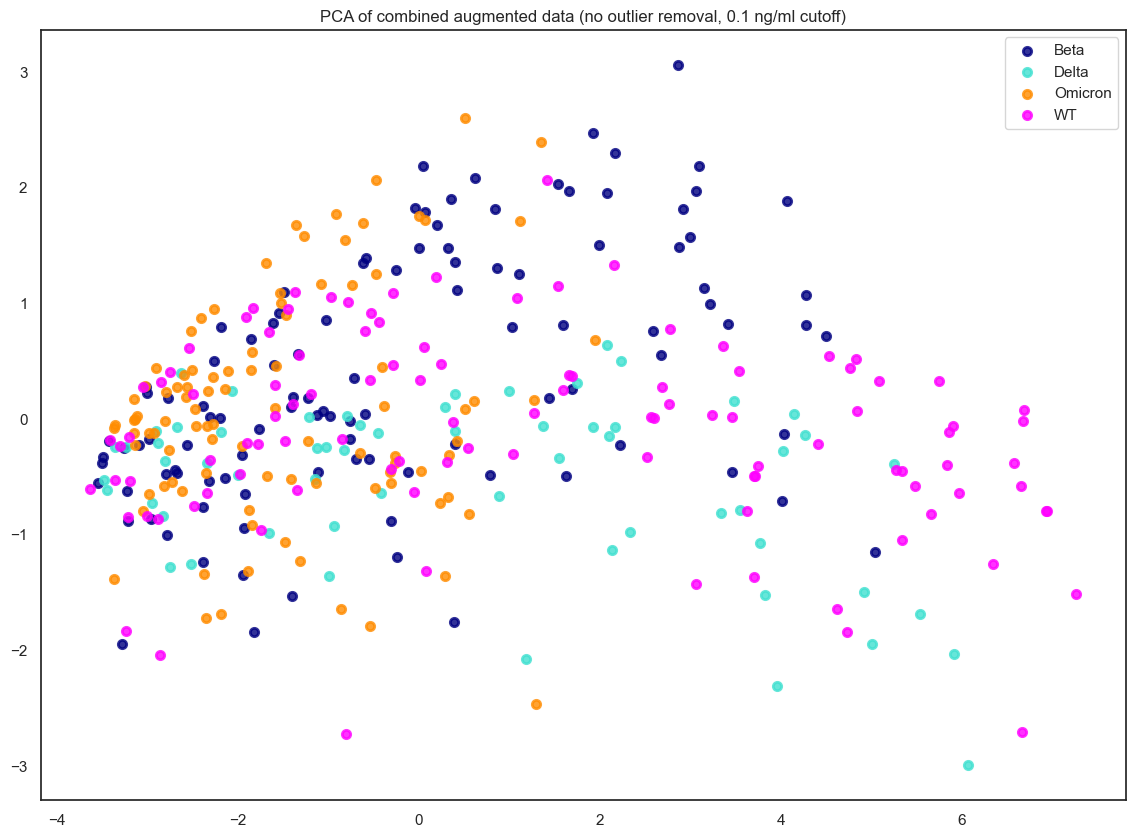

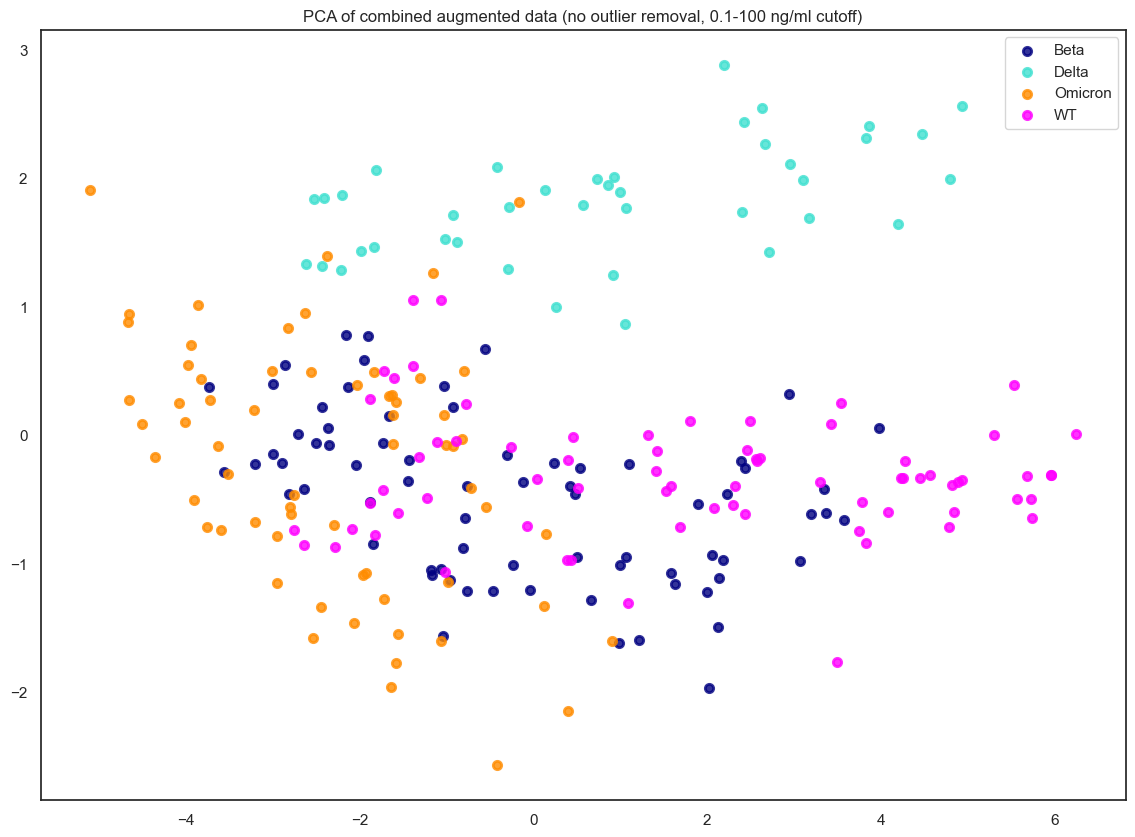

NameError: name 'outlier_trimmed_normalize_cab_fluorescence' is not defined

In [10]:
# PCA
def plot_pca(scaled_dataset,
        colors = ["navy", "turquoise", "darkorange", 'magenta'],
        true_labels = target_vector_labels,
        plot_title = "PCA of combined augmented data (no outlier removal)"
    ):
    target_vals = np.unique(true_labels)
    pca_mod = PCA(n_components=2)
    pca_decomp = pca_mod.fit_transform(scaled_dataset)

    plt.figure()
    lw = 2

    for color, i, target_name in zip(colors, target_vals, true_labels):
        plt.scatter(
            pca_decomp[true_labels == i, 0],
            pca_decomp[true_labels == i, 1],
            color = color, alpha = 0.8,
            lw=lw, label = i
        )
    plt.legend(loc="best", shadow=False, scatterpoints=1)
    plt.title(plot_title)
    plt.show()


plot_pca(normalized_cab_fluorescence,
         plot_title = "PCA of combined augmented data (no outlier removal)")

plot_pca(trimmed_normalized_cab_fluorescence,
         true_labels=trimmed_data_y_labels,
         plot_title = "PCA of combined augmented data (no outlier removal, 0.1 ng/ml cutoff)")

plot_pca(medium_trimmed_normalize_cab_fluorescence,
         true_labels = medium_trimmed_data_y_labels,
         plot_title= "PCA of combined augmented data (no outlier removal, 0.1-100 ng/ml cutoff)")

plot_pca(outlier_trimmed_normalize_cab_fluorescence,
         true_labels = outlier_trimmed_data_y_labels,
         plot_title = "PCA of combined augmented data (kNN imputed) (no outlier removal, 0.1-100 ng/ml cutoff)")

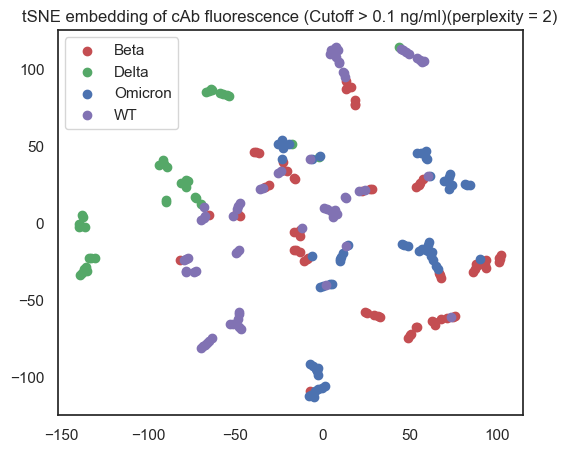

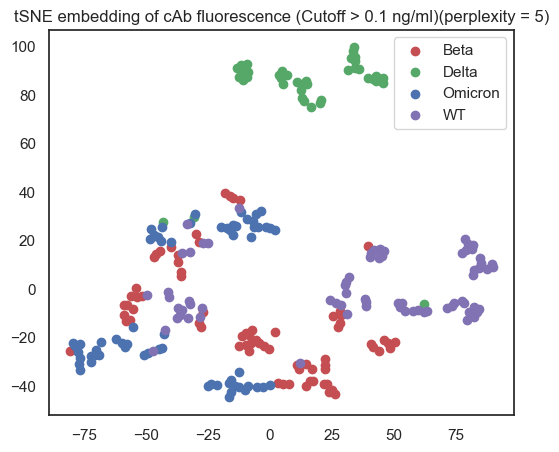

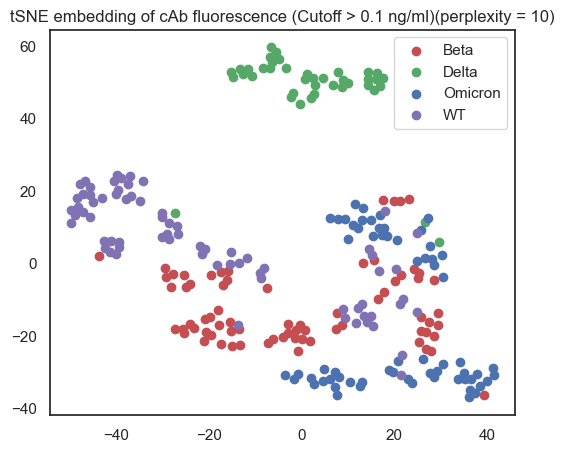

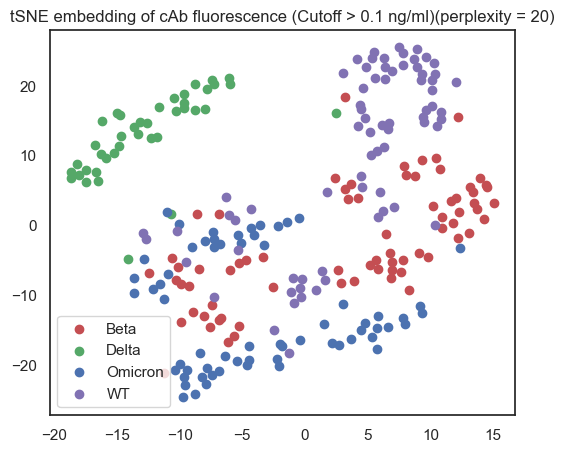

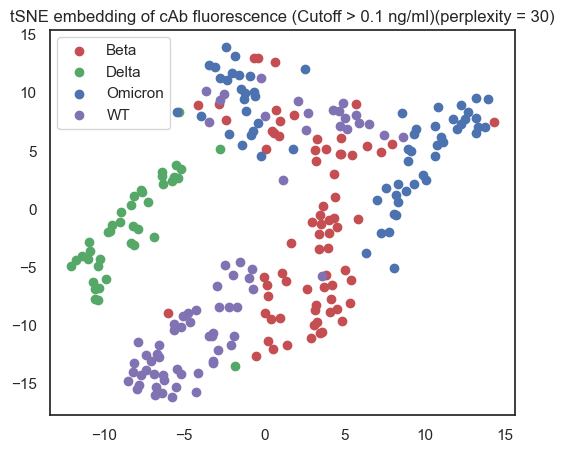

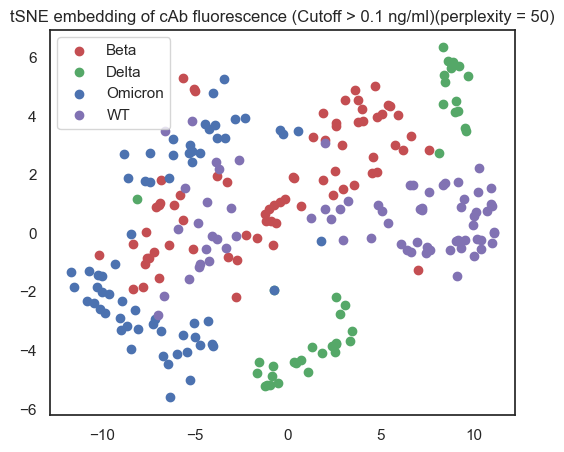

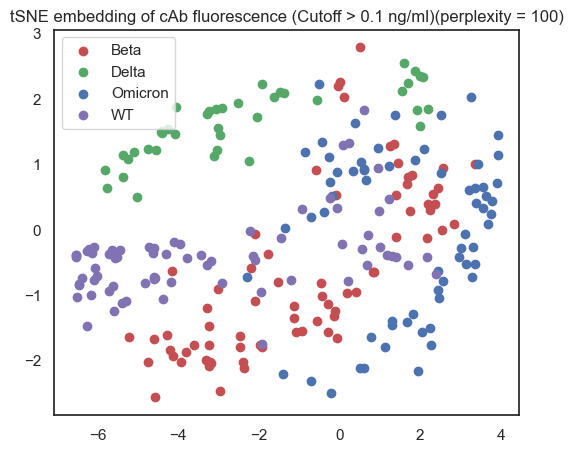

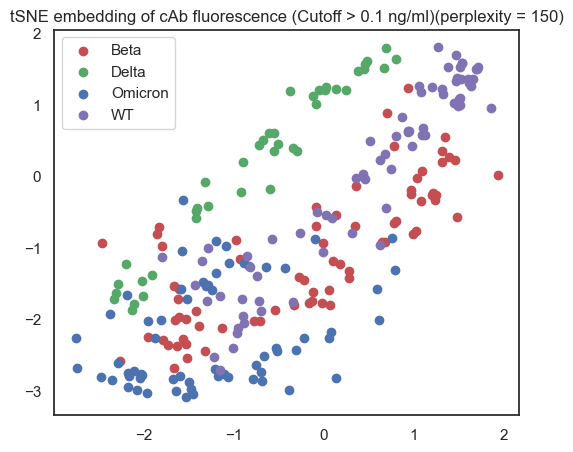

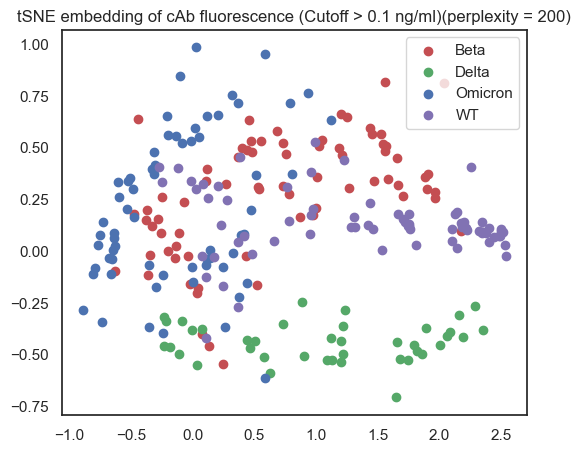

ValueError: perplexity must be less than n_samples

In [11]:
# tSNE
def tsne_opt(scaled_dataset,
             true_labels,
             perplexity_vals = [5, 10, 25, 50], 
             n_iterations = 5000, 
             colors = ['r', 'g', 'b', 'm'],
             plot_title = 'tSNE embedding'):
    
    y_labs = true_labels
    y_vals = np.unique(true_labels)

    tSNE_mods = []
    for perp_val in perplexity_vals:
        plt_title = plot_title
        updated_plot_title = plt_title + f"(perplexity = {perp_val})"
        tsne_mod = TSNE(n_components = 2,
                                    learning_rate= 'auto',
                                    init = 'random',
                                    perplexity = perp_val,
                                    n_iter = n_iterations)
        
        tsne_embedded_fluorescence = tsne_mod.fit_transform(scaled_dataset)
        tSNE_mods.append(tsne_embedded_fluorescence)

        plt.figure(figsize=(6,5))

        for i, c, label in zip(y_vals, colors, y_labs):
            plt.scatter(
                tsne_embedded_fluorescence[y_labs == i, 0], 
                tsne_embedded_fluorescence[y_labs == i, 1], 
                c=c, label=i)
        plt.title(updated_plot_title)
        plt.legend()
        plt.show()

def tsne_opt2(scaled_dataset,
             true_labels,
             perplexity_vals = [5, 10, 25, 50], 
             n_iterations = 5000, 
             colors = ['r', 'g', 'b', 'm'],
             plot_title = 'tSNE embedding',
             subplot_dims = tuple()):
    
    # Set up subplot (subplot dims should be provided as number of rows, cols in a tuple)
    fig, axs = plt.subplots(subplot_dims[0], subplot_dims[1], figsize=(12,10))
    fig.suptitle(f"{plot_title} {n_iterations} iterations")
    
    y_labs = true_labels
    y_vals = np.unique(true_labels)

    tSNE_mods = []
    for perp_val in perplexity_vals:
        updated_plot_title = f"(perplexity = {perp_val})"
        tsne_mod = TSNE(n_components = 2,
                                    learning_rate= 'auto',
                                    init = 'random',
                                    perplexity = perp_val,
                                    n_iter = n_iterations)
        
        tsne_embedded_fluorescence = tsne_mod.fit_transform(scaled_dataset)
        tSNE_mods.append(tsne_embedded_fluorescence)

        for i, c, label in zip(y_vals, colors, y_labs):
            axs.scatter(
                tsne_embedded_fluorescence[y_labs == i, 0], 
                tsne_embedded_fluorescence[y_labs == i, 1], 
                c=c, label=i)
        fig.title(updated_plot_title)
        fig.legend()
    plt.show()

# tsne_opt2(scaled_dataset=normalized_cab_fluorescence,
#          true_labels = target_vector_labels,
#          perplexity_vals = [2, 5, 10, 20, 30, 50, 100, 150, 200, 250],
#          plot_title='tSNE embedding of cAb fluorescence',
#          subplot_dims = (2, 5))

# It seems like across all data sets that perplexity values between 10 and 30 seems to provide the best class-based clustering. Any higher than that and almost no discernible clustering occurs.
# Below 10 and clustering occurs, but points are tightly overlapped and clusters are much more dispersed
tsne_opt(scaled_dataset=medium_trimmed_normalize_cab_fluorescence,
         true_labels=medium_trimmed_data_y_labels,
         perplexity_vals = [2, 5, 10, 20, 30, 50, 100, 150, 200, 250],
         plot_title='tSNE embedding of cAb fluorescence (Cutoff > 0.1 ng/ml)')

# tSNE with PCA scores as input to help reduce noise - also "stabilizes" the tSNE so random state initialization doesn't change the results
# tsne_opt(scaled_dataset = augmented_data_pca,
#          true_labels = target_vector_labels,
#          perplexity_vals = [2, 5, 10, 20, 30, 50, 100, 150, 200, 250],
#          plot_title='tSNE embedding of cAb fluorescence PCA scores')

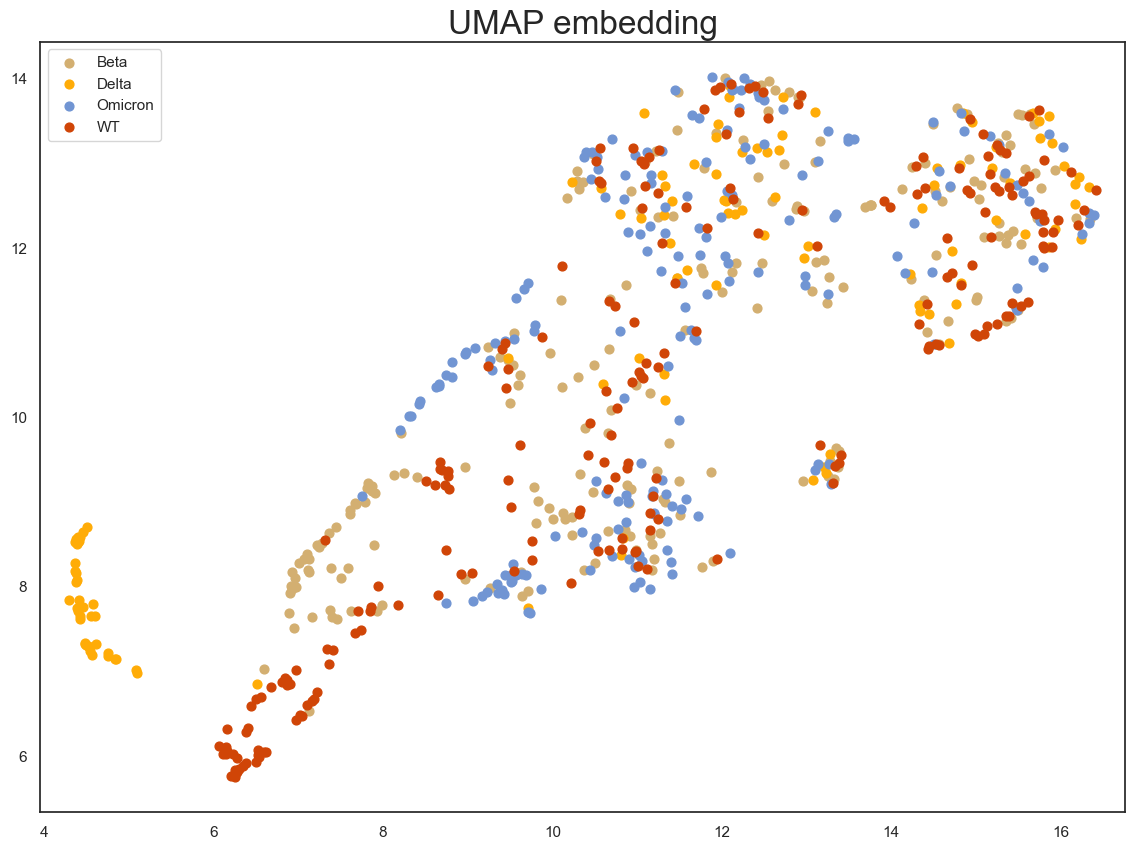

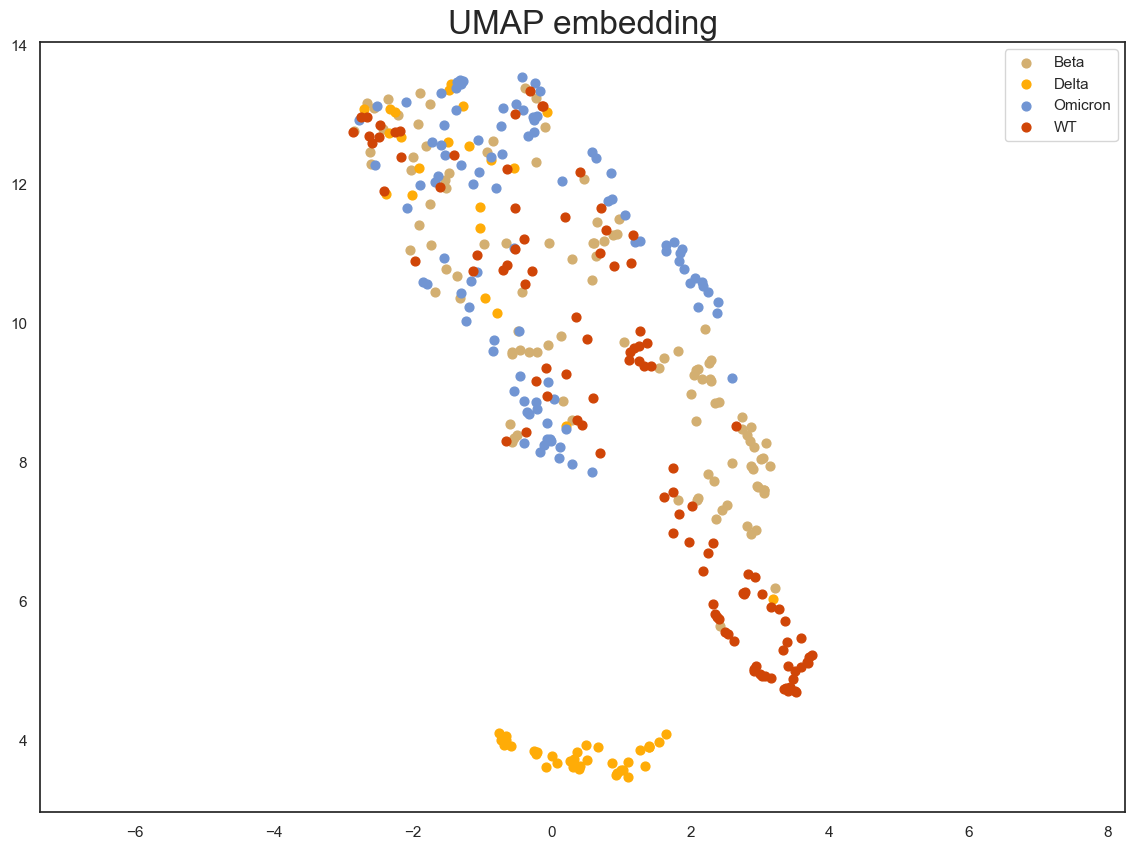

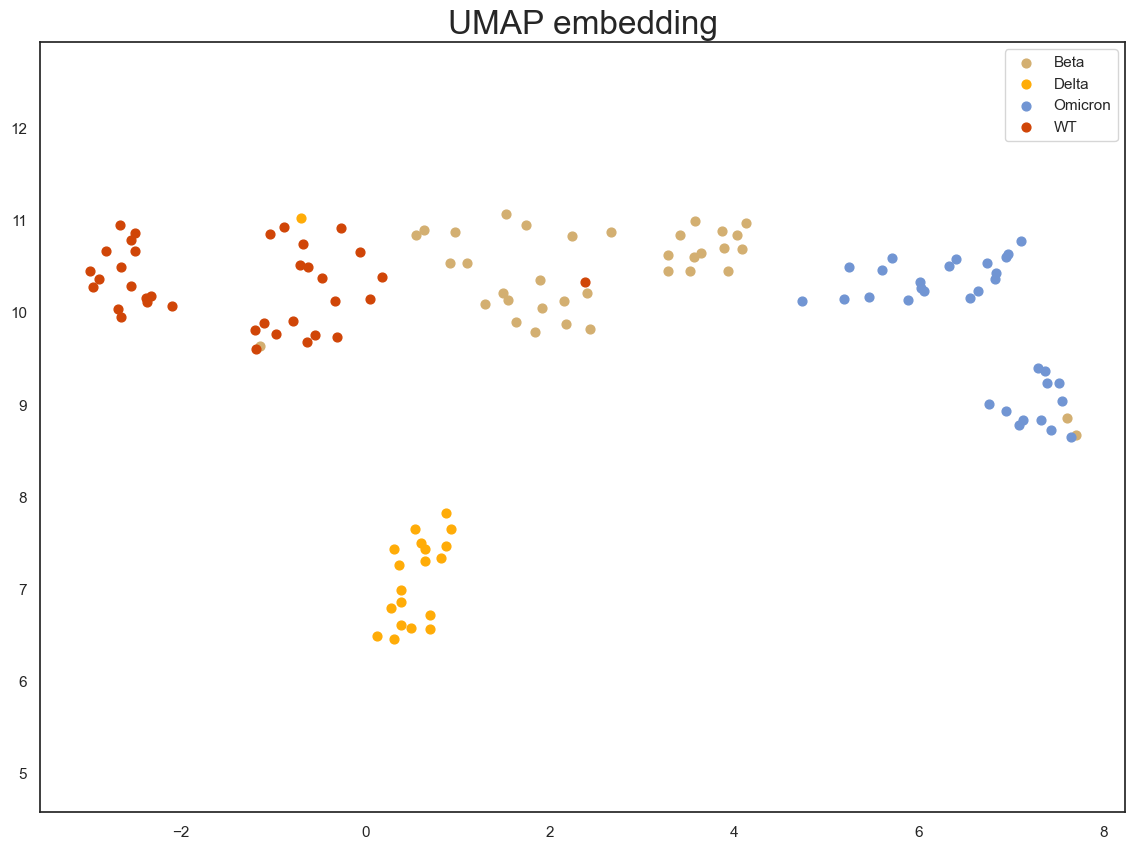

In [14]:
def umap_reducer(scaled_dataset,
                 true_y_labels,
                #  parameter_grid,
                 colors = ['#D3AF71', '#FFAC07', '#7195D3', '#D04507'],
                 plot_title = 'UMAP embedding'):
    
    y_labs = true_y_labels
    y_vals = np.unique(true_y_labels)

    reducer = umap.UMAP(n_neighbors=20,
                        min_dist = 0.1)
    umap_embedding = reducer.fit_transform(scaled_dataset)

    for i, c, label in zip(y_vals, colors, y_labs):
        plt.scatter(
            umap_embedding[y_labs == i, 0], 
            umap_embedding[y_labs == i, 1], 
            c=c, label=i,
            s=40)
    
    plt.legend()
    plt.gca().set_aspect('equal', 'datalim')
    plt.title(plot_title, fontsize=24)
    plt.show()



umap_reducer(normalized_cab_fluorescence,
             target_vector_labels
             )

umap_reducer(trimmed_normalized_cab_fluorescence,
             trimmed_data_y_labels
             )

umap_reducer(medium_trimmed_normalize_cab_fluorescence,
             medium_trimmed_data_y_labels
             )

# umap_reducer(outlier_trimmed_normalize_cab_fluorescence,
  #           outlier_trimmed_data_y_labels)